# 15 · Acquisition functions (straddle, LSE, misclassification, contour criteria, SUR, failure-seeking EI, portfolios, unknown constraints)

**Theory:** Bryan et al. 2005; Gotovos et al. 2013; Bect et al. 2012; Lyu, Binois & Ludkovski 2021 (full references at the
end). For a boundary, the useful question is "where am I unsure which side of the threshold the
point is on?" The criteria below answer it differently, mostly through t = |μ − h|/σ, and differ in how much they explore.
Harness: `failreg/acquisition.py` (notebook 32). CPU only, about three minutes.

| Criterion | Score (run where largest) | Source |
|---|---|---|
| straddle | 1.96σ − \|μ − h\| | Bryan et al. 2005 |
| MCU | γσ − \|μ − h\|, γ = IQR(μ)/(3·mean σ) | Lyu et al. 2021, eq. 3.1 and their recipe |
| MEE | Φ(−\|μ − h\|/σ) | Lyu et al. 2021, eq. 3.2 |
| EFF / contour EI | E[max(0, ε^δ − \|h − G\|^δ)], ε = κσ; δ = 1 Bichon, δ = 2 Ranjan | Bect et al. 2012, eq. 31 |
| tIMSE | variance reduction weighted by φ((μ − h)/σ)/σ | Bect et al. 2012, eq. 28–29 |
| SUR (J₁) | expected integrated misclassification after one more run, Gauss–Hermite over the future run | Bect et al. 2012, Table 1 |
| EI (failure-seeking) | expected improvement below the lowest margin | Jones et al. 1998 |
| LSE | ambiguity of intersected intervals μ ± β^½σ; classify with accuracy ε | Gotovos et al. 2013 |
| GP-Hedge | portfolio, pick ∝ exp(η·gain) | Hoffman et al. 2011 |

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
HERE = Path.cwd().resolve()
HERE = HERE if (HERE / "failreg").exists() else HERE / "notebooks/course"
sys.path.insert(0, str(HERE))
from failreg import problems as P, metrics as M, designs as D, models as MD, acquisition as A, replication as R, loop as L, plots as PL
warnings.filterwarnings("ignore")
PL.style(); T0 = time.time()

## 1. Where each criterion would run next

One GP fitted to 15 Sobol' runs on Branin (threshold 10); the score of each criterion on a 41 × 41 grid; the star is the argmax.

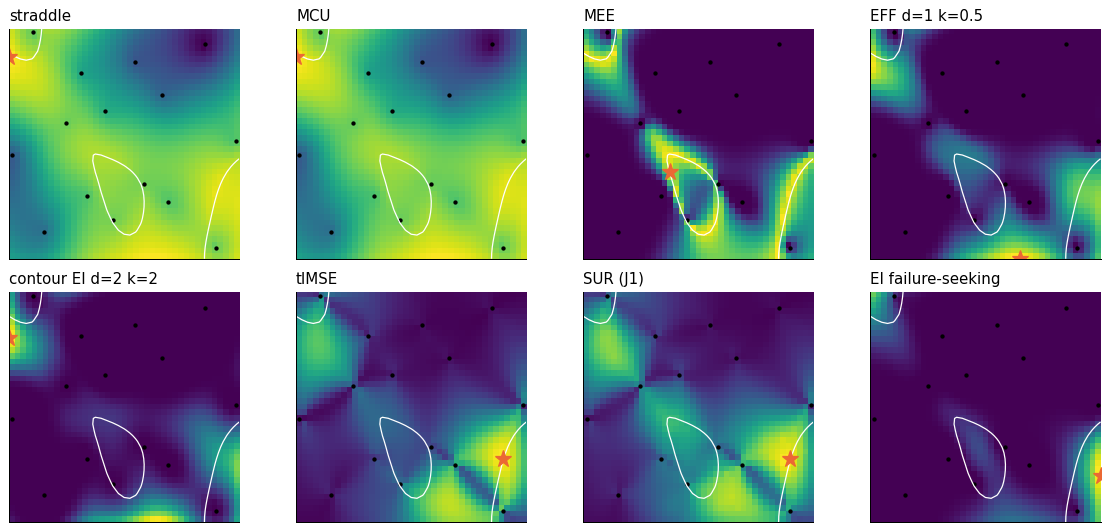

MCU gamma at this step: 2.09 (straddle uses 1.96)
MEE is 0.5 everywhere on the estimated boundary, so it has no unique maximiser (Lyu et al.): ties broken by order.


In [2]:
pb = P.get("branin")
X0 = D.sobol(15, 2, 0); m0 = MD.GPR().fit(X0, pb.f(X0))
Gc = pb.grid(41); mu, sd = m0.predict(Gc); h = pb.tau; ref = D.sobol(256, 2, 99)
best = pb.f(X0).min()
SC = {"straddle": A.straddle(mu, sd, h), "MCU": A.mcu(mu, sd, h), "MEE": A.mee(mu, sd, h),
      "EFF d=1 k=0.5": A.contour_ei(mu, sd, h, 0.5, 1), "contour EI d=2 k=2": A.contour_ei(mu, sd, h, 2.0, 2),
      "tIMSE": A.timse(m0, Gc, ref, h), "SUR (J1)": A.sur(m0, Gc, ref, h), "EI failure-seeking": A.ei_fail(mu, sd, best)}
fig, axs = plt.subplots(2, 4, figsize=(13, 6))
for ax, (k, v) in zip(axs.ravel(), SC.items()):
    ax.imshow(v.reshape(41, 41).T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
    ax.contour(np.linspace(0, 1, 41), np.linspace(0, 1, 41), (mu - h).reshape(41, 41).T, levels=[0], colors="w", linewidths=1)
    i = np.argmax(v); ax.plot(*Gc[i], "*", color=PL.ORANGE, ms=14); ax.scatter(X0[:, 0], X0[:, 1], s=6, c="k")
    ax.set_title(k, loc="left"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
print("MCU gamma at this step:", round(A.mcu_gamma(mu, sd), 2), "(straddle uses 1.96)")
print("MEE is 0.5 everywhere on the estimated boundary, so it has no unique maximiser (Lyu et al.): ties broken by order.")

## 2. Benchmark at equal budget

Branin (three regions), 40 runs: 10 Sobol' points, then batches of 5 (the 5 best by score, at least 0.02 apart). SUR and
tIMSE score the 64 pool points with the largest MEE and take their 5 best: a one-point criterion used for a batch, not a
batch SUR, which handicaps them. 5 paired seeds; Sobol' to 40 runs is the baseline. With 5 seeds, read the table as a
description, not a ranking (notebook 32).

In [3]:
REF = D.sobol(256, 2, 99)
def lookahead(crit):
    def pick(problem, model, pool, X, y, k, state):
        mu, sd = model.predict(pool); top = np.argsort(-A.mee(mu, sd, L.threshold(problem, model, pool)))[:64]
        s = crit(model, pool[top], REF, L.threshold(problem, model, REF))
        return top[L.select(s, pool[top], X, k, 0.02)]
    return pick
def ei_pick(problem, model, pool, X, y, k, state):
    mu, sd = model.predict(pool); return L.select(A.ei_fail(mu, sd, np.nanmin(y)), pool, X, k, 0.02)
ARMS = {"straddle": L.by_score(A.straddle), "MCU": L.by_score(A.mcu), "MEE": L.by_score(A.mee),
        "EFF d=1 k=0.5": L.by_score(lambda m, s, h: A.contour_ei(m, s, h, 0.5, 1)), "cEI d=2 k=2": L.by_score(lambda m, s, h: A.contour_ei(m, s, h, 2.0, 2)),
        "tIMSE": lookahead(A.timse), "SUR (J1)": lookahead(A.sur), "EI fail-seeking": ei_pick}
NS = [10, 20, 30, 40]; gp = lambda: MD.GPR(); t = time.time()
HB = {a: [L.active(pb, gp, f, 40, s, n0=10, batch=5, checkpoints=NS)[0] for s in range(5)] for a, f in ARMS.items()}
HB["Sobol'"] = [L.static(pb, D.sobol, 40, s, gp, NS)[0] for s in range(5)]
print(f"{time.time() - t:.0f} s")
print(f"{'arm':16s}" + "".join(f"{'n=' + str(n):>9s}" for n in NS[1:]) + "   misclassified %, median of 5 seeds;  false-safe at 40")
for a, hs in HB.items():
    print(f"{a:16s}" + "".join(f"{100*np.median(L.table(hs, 'misclassified', n)):9.3f}" for n in NS[1:]) + f"   {np.median(L.table(hs, 'false_safe', 40)):.3f}")

62 s
arm                  n=20     n=30     n=40   misclassified %, median of 5 seeds;  false-safe at 40
straddle            5.509    0.667    0.176   0.004
MCU                 5.509    0.961    0.284   0.005
MEE                 5.970    0.569    0.167   0.006
EFF d=1 k=0.5       5.872    0.637    0.206   0.004
cEI d=2 k=2         7.715    0.794    0.176   0.004
tIMSE               6.215    1.010    0.333   0.016
SUR (J1)            5.068    1.294    0.373   0.012
EI fail-seeking     7.715    1.392    0.598   0.018
Sobol'              4.519    0.647    0.412   0.012


## 3. Exploration: are all regions found?

Four-branch (four regions), 30 runs, 3 seeds. Failure-seeking EI goes for the lowest margin, not the region; criteria that
discount regions far from the current boundary can miss a branch. On this problem every criterion finds all four
branches by 30 runs (the 10 Sobol' points already touch each), and the misclassified share separates them.

In [4]:
p4 = P.get("four_branch"); G4, t4, sh4, _ = p4.test; t = time.time()
for a in ("straddle", "MEE", "SUR (J1)", "EI fail-seeking"):
    found, mis = [], []
    for s in range(3):
        h_, X, y, m = L.active(p4, gp, ARMS[a], 30, s, n0=10, batch=5)
        found.append(M.mechanisms_found(t4, L.region(p4, m, G4), sh4)[0]); mis.append(100 * h_[-1]["misclassified"])
    print(f"{a:16s} regions found of 4: {found}   misclassified %: {np.round(mis, 2)}")
print(f"{time.time() - t:.0f} s")

straddle         regions found of 4: [4, 4, 4]   misclassified %: [9.4  4.67 8.82]


MEE              regions found of 4: [4, 4, 4]   misclassified %: [3.97 2.51 5.18]


SUR (J1)         regions found of 4: [4, 4, 4]   misclassified %: [9.46 6.13 8.55]


EI fail-seeking  regions found of 4: [4, 4, 4]   misclassified %: [11.03  9.95 13.76]
12 s


## 4. LSE (Gotovos et al. 2013)

A fixed candidate set; intervals μ ± β^½σ are intersected over time; a point is classified failing once its interval's
top is below h + ε, safe once its bottom is above h − ε; the next runs go to the unclassified points with the largest
ambiguity. β^½ = 3 as in their experiments, ε = 0.5. Before any intersection the ambiguity equals the straddle at
β^½ = 1.96 (tested in `tests/test_course_harness.py`).

In [5]:
C = D.sobol(1024, 2, 7)
def lse_pick(problem, model, pool, X, y, k, state):
    if "lse" not in state: state["lse"] = A.LSE(len(C), problem.tau, beta_sqrt=3.0, eps=0.5); state["hist"] = []
    mu, sd = model.predict(C); state["lse"].update(mu, sd); state["hist"].append((len(X), state["lse"].unclassified.mean()))
    return L.select(state["lse"].ambiguity(), C, X, k, 0.02)
st = {}; h_, X, y, m = L.active(pb, gp, lse_pick, 60, 0, n0=10, batch=5, state=st)
lse = st["lse"]; truth_C = pb.fails(C)
print("unclassified share after n runs:", [(n, round(u, 3)) for n, u in st["hist"]])
cls = lse.fail | lse.safe
print(f"LSE's own classification: {cls.mean():.1%} of candidates classified, wrong on {np.mean(lse.fail[cls] != truth_C[cls]):.2%} of those;"
      f" GP region misclassified {100*h_[-1]['misclassified']:.3f} %")

unclassified share after n runs: [(10, 0.642), (15, 0.48), (20, 0.293), (25, 0.218), (30, 0.183), (35, 0.156), (40, 0.149), (45, 0.142), (50, 0.139), (55, 0.135)]
LSE's own classification: 86.5% of candidates classified, wrong on 0.00% of those; GP region misclassified 0.529 %


## 5. Edge oversampling, and naive batches

Straddle "is also subject to oversampling edge positions" (Bryan et al. 2005): σ is largest at the box edges. Compare the
share of straddle's runs within 0.05 of the edge with that band's share of the box (19 %).

Batches: the top 10 points of one score are redundant; Gotovos et al. build a batch greedily and shrink σ for the pending
points (the GP variance does not depend on the outcome). 60 runs in batches of 10, 5 seeds.

In [6]:
edge = lambda Z: np.mean(np.min(np.minimum(Z, 1 - Z), axis=1) < 0.05)
_, X, _, _ = L.active(pb, gp, L.by_score(A.straddle, min_dist=0.0), 60, 0, n0=10, batch=5)
print(f"straddle runs near the edge: {edge(X[10:]):.0%} (band area 19 %)")
def topb(problem, model, pool, X, y, k, state):
    mu, sd = model.predict(pool); return L.select(A.straddle(mu, sd, problem.tau), pool, X, k, 0.0)
def pending(problem, model, pool, X, y, k, state):
    return A.pending_batch(model, pool, problem.tau, k)
t = time.time()
for name, f in (("naive top-10", topb), ("pending-variance batch", pending)):
    mis, spread = [], []
    for s in range(5):
        h_, X, y, _ = L.active(pb, gp, f, 60, s, n0=10, batch=10)
        mis.append(100 * h_[-1]["misclassified"])
        b = X[-10:]; spread.append(np.median([np.sort(np.linalg.norm(b - b[i], axis=1))[1] for i in range(10)]))
    print(f"{name:24s} misclassified % median {np.median(mis):.3f}; nearest-neighbour distance inside the last batch {np.median(spread):.3f}")
print(f"{time.time() - t:.0f} s")

straddle runs near the edge: 36% (band area 19 %)


naive top-10             misclassified % median 0.049; nearest-neighbour distance inside the last batch 0.037


pending-variance batch   misclassified % median 0.029; nearest-neighbour distance inside the last batch 0.120
14 s


## 6. A portfolio: GP-Hedge

Each criterion (straddle, MEE, failure-seeking EI) nominates a batch; one is run, chosen with probability ∝ exp(η·gain),
η = 1. Hoffman et al. reward each nominee with the updated GP mean there, which suits maximisation, not a boundary. Here the
reward is −mean |μ' − h|/sd(y) at the nominees under the refitted model (own choice; a boundary reward is an open question).

In [7]:
NOM = {"straddle": lambda mu, sd, h, y: A.straddle(mu, sd, h), "MEE": lambda mu, sd, h, y: A.mee(mu, sd, h), "EI": lambda mu, sd, h, y: A.ei_fail(mu, sd, np.nanmin(y))}
def hedge_pick(problem, model, pool, X, y, k, state):
    hed = state.setdefault("hedge", A.GPHedge(list(NOM), eta=1.0, seed=state["seed"]))
    if "nominees" in state:
        hed.update([-np.mean(np.abs(model.predict(Z)[0] - problem.tau)) / np.nanstd(y) for Z in state["nominees"]])
    mu, sd = model.predict(pool)
    idx = [L.select(f(mu, sd, problem.tau, y), pool, X, k, 0.02) for f in NOM.values()]
    state["nominees"] = [pool[i] for i in idx]
    return idx[hed.choose()]
res = []
for s in range(3):
    st = {"seed": s}; h_, *_ = L.active(pb, gp, hedge_pick, 40, s, n0=10, batch=5, state=st)
    res.append(100 * h_[-1]["misclassified"]); print(f"seed {s}: picks {st['hedge'].picks}, final probabilities {np.round(st['hedge'].probs(), 2)}")
print("GP-Hedge misclassified % at 40 runs:", np.round(res, 3))

seed 0: picks ['MEE', 'straddle', 'straddle', 'straddle', 'EI', 'EI'], final probabilities [0.34 0.41 0.25]


seed 1: picks ['MEE', 'EI', 'straddle', 'EI', 'MEE', 'MEE'], final probabilities [0.27 0.5  0.23]


seed 2: picks ['straddle', 'straddle', 'EI', 'straddle', 'MEE', 'EI'], final probabilities [0.21 0.49 0.31]
GP-Hedge misclassified % at 40 runs: [0.363 0.274 0.265]


## 7. Unknown constraints: runs that do not realise

Branin where every run with x₁ > 0.7 and x₂ < 0.35 crashes (returns no margin). A GP classifier learns P(valid) from the
runs so far; the straddle score is multiplied by it (Gardner et al. 2014; Gelbart et al. 2014). Scored on the valid part
of the box. 50 runs, 5 seeds. Without the weight, a crashed run returns no data, the GP stays unsure there, and the
criterion keeps sending runs into the crash region.

In [8]:
pv = P.get("branin"); G, truth, shape, _ = pv.test
invalid = lambda U: (np.atleast_2d(U)[:, 0] > 0.7) & (np.atleast_2d(U)[:, 1] < 0.35)
base_run = pv.run
pv.run = lambda U, rng: np.where(invalid(U), np.nan, base_run(U, rng))
pv._test = (G, truth, shape, ~invalid(G))
def weighted(problem, model, pool, X, y, k, state):
    mu, sd = model.predict(pool); s = A.straddle(mu, sd, problem.tau)
    v = np.isfinite(y).astype(int)
    if 0 < v.mean() < 1:
        s = A.weight_valid(s, MD.GPC().fit(X, v).p_fail(pool))
    return L.select(s, pool, X, k, 0.02)
for name, f in (("straddle", L.by_score(A.straddle)), ("straddle x P(valid)", weighted)):
    lost, mis = [], []
    for s in range(5):
        h_, X, y, _ = L.active(pv, gp, f, 50, s, n0=10, batch=5)
        lost.append(int(np.sum(~np.isfinite(y[10:])))); mis.append(100 * h_[-1]["misclassified"])
    print(f"{name:22s} crashed runs after the initial design (of 40): {lost}; misclassified % median {np.median(mis):.3f}")

straddle               crashed runs after the initial design (of 40): [38, 40, 39, 28, 38]; misclassified % median 10.103


straddle x P(valid)    crashed runs after the initial design (of 40): [5, 0, 0, 0, 0]; misclassified % median 0.900


## 8. esmini cut-in

Straddle and MEE against Sobol' on the esmini cut-in slice (ego 30 m/s; fail = minimum TTC below 1.5 s), 50 runs, 3 seeds,
scored against the reference grid.

450 esmini runs in 29 s
straddle  misclassified % at [20, 30, 40, 50]: [1.35, 0.91, 0.44, 0.34]  false-safe at 50: 0.023
MEE       misclassified % at [20, 30, 40, 50]: [1.86, 0.68, 0.37, 0.24]  false-safe at 50: 0.011
Sobol'    misclassified % at [20, 30, 40, 50]: [2.13, 2.26, 2.16, 1.72]  false-safe at 50: 0.077


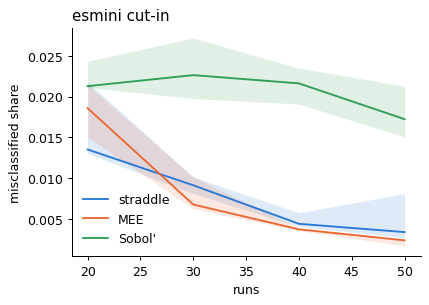

In [9]:
from failreg import esmini_case as E
ec = E.cutin(); NE = [20, 30, 40, 50]; t = time.time()
HE = {a: [L.active(ec, gp, ARMS[a], 50, s, n0=10, batch=5, checkpoints=NE)[0] for s in range(3)] for a in ("straddle", "MEE")}
HE["Sobol'"] = [L.static(ec, D.sobol, 50, s, gp, NE)[0] for s in range(3)]
print(f"{ec.calls} esmini runs in {time.time() - t:.0f} s")
for a, hs in HE.items():
    print(f"{a:9s} misclassified % at {NE}:", [round(100 * np.median(L.table(hs, 'misclassified', n)), 2) for n in NE],
          " false-safe at 50:", round(np.median(L.table(hs, 'false_safe', 50)), 3))
fig, ax = plt.subplots(figsize=(5, 3.3))
PL.curves(ax, NE, {a: [[r["misclassified"] for r in h] for h in hs] for a, hs in HE.items()}, "misclassified share"); ax.set_title("esmini cut-in", loc="left"); plt.show()

## References

- B. Bryan, J. Schneider, R. Nichol, C. Miller, C. Genovese, L. Wasserman, "Active Learning for Identifying Function Threshold Boundaries," NIPS 2005 (straddle; edge oversampling).
- A. Gotovos, N. Casati, G. Hitz, A. Krause, "Active Learning for Level Set Estimation," IJCAI 2013 (LSE; batches with pending variance).
- X. Lyu, M. Binois, M. Ludkovski, "Evaluating Gaussian Process Metamodels and Sequential Designs for Noisy Level Set Estimation," Statistics and Computing 31, 2021 (MCU, MEE, adaptive γ).
- J. Bect, D. Ginsbourger, L. Li, V. Picheny, E. Vazquez, "Sequential design of computer experiments for the estimation of a probability of failure," Statistics and Computing 22, 2012, arXiv:1009.5177 (the δ, κ family; tIMSE; SUR).
- M. Hoffman, E. Brochu, N. de Freitas, "Portfolio Allocation for Bayesian Optimization," UAI 2011, arXiv:1009.5419 (GP-Hedge).
- M. A. Gelbart, J. Snoek, R. P. Adams, "Bayesian Optimization with Unknown Constraints," UAI 2014, arXiv:1403.5607 (probabilistic constraints; crashes as constraints).
- J. R. Gardner, M. J. Kusner, Z. Xu, K. Q. Weinberger, J. P. Cunningham, "Bayesian Optimization with Inequality Constraints," ICML 2014.
- H. Tu, S. Suo, L. Zhang, K. Wong, R. Urtasun, "Towards Scalable Coverage-Based Testing of Autonomous Vehicles," CoRL 2023 (variance-only first phase).
- D. R. Jones, M. Schonlau, W. J. Welch, "Efficient Global Optimization of Expensive Black-Box Functions," J. Global Optimization 13, 1998 (EI).

In [10]:
print(f"notebook ran in {time.time() - T0:.0f} s")

notebook ran in 150 s
